# Algorithm-choice coding bench: source-data builder (`data.py`), demo run

This notebook runs `data.py` from the dataset artifact *Source data for an algorithm-choice coding bench*. The bench asks **which algorithm an LLM picks for a coding task** (Dijkstra, BFS, quickselect, KMP, ...) and **where it goes when that choice is banned in the prompt**. `data.py` collects the external data the bench is built from. It standardises 10 downloaded public sources into one `exp_sel_data_out` file, `full_data_out.json`: 10 datasets, 61,469 examples, 96.2 MB.

**What `data.py` does.** Every source row becomes one example `{input, output, metadata_*}`, grouped by dataset. Along the way it does four things:
- It maps LeetCode problems to bench tasks T01–T14 and R1–R6. For example, LeetCode 743 *network delay time* maps to T02 *weighted shortest path*.
- For each bench-mapped problem, it parses every recorded input/output pair into keyword arguments plus an expected value. These are the bench's hidden-test seeds. It also re-runs the dataset's reference solution against its own `check()` in an isolated `python -I` subprocess.
- It tags implementations (TheAlgorithms, Mercury, XLCoST, KodCode, CLRS traces) with the algorithm *modes* their names mention.
- It builds a noun bank for neutral-twin and context-seed prompts.

**What this demo runs.** The full build needs about 1.4 GB of raw downloads. This demo instead loads `mini_demo_data.json`, which holds **100 raw rows of one source, LeetCodeDataset** (`newfacade/LeetCodeDataset` at revision `215604a`, Apache-2.0; Xia et al. 2025, arXiv:2504.14655):
- all 20 bench-mapped problems;
- 10 other *Shortest Path* problems;
- 70 diverse problems from the train and test splits.

The notebook runs the original `build_leetcodedataset` and `main()` on these rows. It then compares every rebuilt example with the one in the published `full_data_out.json`.

**How the code differs from `data.py`.** The code cells are `data.py` split into sections. The only changes are marked with `# Notebook:` comments:
- the rows are read from the loaded data instead of `temp/datasets/`;
- there is no `__file__`;
- the command-line options come from the config cell.

The notebook runs in well under a minute, plus the install cell.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT on Colab, always install (data.py's PEP 723 header pins loguru==0.7.3)
_pip('loguru==0.7.3')

# Pre-installed on Colab, install locally only, at Colab's versions:
#   numpy, pandas, matplotlib: the results cell
#   tokenizers, huggingface_hub: imported lazily by qwen3_tokenizer() (noun bank, not run in this demo);
#   data.py's header pins tokenizers==0.23.3 and huggingface-hub==2.2.0
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
# Notebook: data.py's module docstring (main() uses its first line as the argparse description)
__doc__ = """Standardise the downloaded sources into one exp_sel_data_out file (full_data_out.json).

Every row of a source (or of its documented domain subset) becomes one example
{input, output, metadata_*}; examples are grouped by source dataset. Domain handling for the
algorithm-choice coding bench:

* LeetCode-derived rows are mapped to bench tasks (T01-T14, R1-R6). For the bench-mapped
  LeetCodeDataset problems every input_output pair is parsed into keyword arguments plus an
  expected value (case id leetcodedataset:<question_id>:<idx>), and the dataset's own reference
  solution is re-run against its check() in an isolated `python -I` subprocess.
* Implementations (TheAlgorithms, Mercury, XLCoST, KodCode, CLRS traces) carry the
  algorithm modes their path/title/question names (a text match, not a verified label) and, for
  TheAlgorithms, a hand-checked bench mode.
* llm-creativity states no licence: only program paths, the commit and the repository's judge
  labels are stored, never program text.
* The noun bank (Brysbaert concreteness norms) gets Qwen3 token counts and Open English WordNet
  noun classes, and flags candidates for neutral-twin / context-seed nouns.

Only the 10 datasets chosen in the selection stage are built (reasons in README.md and
DATASET_SELECTION.md); scripts/selection_stage_data_all15.py is the 15-source version that was run to
make that choice.

Run:  uv run data.py                                   # all 10 chosen datasets -> full_data_out.json
      uv run data.py --datasets leetcodedataset,mercury # a subset (written to --out)
"""

import argparse
import ast
import functools
import hashlib
import json
import re
import resource
import subprocess
import sys
import time
import warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from loguru import logger

# Notebook additions: glob matching over the loaded demo data (load_rows) and the results cell
import fnmatch

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-1/dataset-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"], "|", data["metadata"]["source"])
for f, rows in data["source_files"].items():
    print(f"  temp/datasets/{f}: {len(rows)} raw rows")

GitHub data unavailable, using local mini_demo_data.json: <urlopen error [Errno 111] Connection refused>
Mini demo data for data.py: 100 raw LeetCodeDataset rows | {'repo': 'newfacade/LeetCodeDataset', 'revision': '215604aeed660029df7de2fea5a4d7b6ed476a08', 'licence': 'Apache-2.0', 'paper': 'Xia et al. 2025, arXiv:2504.14655'}
  temp/datasets/leetcodedataset/full_newfacade_LeetCodeDataset_default_train.json: 70 raw rows
  temp/datasets/leetcodedataset/full_newfacade_LeetCodeDataset_default_test.json: 30 raw rows


## Configuration

`data.py` is a command-line script. Its five options become variables here and reach `main()` as the argument list `ARGV`, so `main()` itself is unchanged apart from reading `ARGV`. The original defaults are in the comments.

`MAX_ROWS_PER_FILE` is the demo's one extra knob: how many rows of each source file (train / test) the builder reads. The train file of the demo data lists the 20 bench-mapped problems first, so even a small value exercises test-case parsing and the reference check.

The demo cannot run the original full scale here: all 2,869 problems and all 10 datasets need the raw downloads. For that, run `bash restore.sh && uv run data.py` in the artifact repository.

In [5]:
# data.py's command-line options (original defaults in the comments)
DATASETS = "leetcodedataset"  # original: "all" (the 10 chosen datasets); the demo data holds LeetCodeDataset rows only
OUT = "demo_data_out.json"    # original: ROOT / "full_data_out.json"
CLRS_PER_LENGTH = 5           # original: 5 (traces kept per (algorithm, length); only clrs_text uses it)
VERIFY = True                 # original: True (--no-verify sets False): re-run the bench-mapped reference solutions
MAX_MB = 95.0                 # original: 95.0 (split the output into parts above this size)

# Demo scale: rows read from each source file of the demo data (70 train rows, bench-mapped first, and 30 test rows).
# None = all 100 (main() takes about 1 s; tested at 1, 10 and None). Original: every raw row, 2,641 train + 228 test,
# from temp/datasets/ (restored by restore.sh in the artifact repository; the 10-dataset build takes about 35 s)
MAX_ROWS_PER_FILE = None

ARGV = ["--datasets", DATASETS, "--out", OUT, "--clrs-per-length", str(CLRS_PER_LENGTH), "--max-mb", str(MAX_MB)]
if not VERIFY:
    ARGV.append("--no-verify")
print("main() will run with:", ARGV, "| MAX_ROWS_PER_FILE =", MAX_ROWS_PER_FILE)

main() will run with: ['--datasets', 'leetcodedataset', '--out', 'demo_data_out.json', '--clrs-per-length', '5', '--max-mb', '95.0'] | MAX_ROWS_PER_FILE = None


## 1. Paths and logging

In `data.py`, `ROOT` is the repository root, `Path(__file__).resolve().parent`. A notebook has no `__file__`, so the working directory takes its place (`/content` on Colab).

`DATA` is `temp/datasets/`, where the artifact's `scripts/download_all.py` stores the raw downloads. In this demo, `load_rows` (section 6) reads the loaded `data` instead.

Logs go to the cell output and to `logs/data.log`.

In [6]:
ROOT = Path.cwd()  # Notebook: no __file__ here (data.py: Path(__file__).resolve().parent)
DATA = ROOT / "temp" / "datasets"
LOG_DIR = ROOT / "logs"
LOG_DIR.mkdir(exist_ok=True)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(LOG_DIR / "data.log", rotation="30 MB", level="DEBUG")
print(f"logging to this output and to {LOG_DIR.name}/data.log")  # Notebook: status line (keeps logger.add's handler id from being echoed)

logging to this output and to logs/data.log


## 2. Bench vocabulary and the LeetCode → bench-task map

This section defines four things:
- **`BENCH_TASKS`**: the bench's 18 task ids, each with a one-line contract.
- **`LEETCODE_BENCH_MAP`**: the LeetCode problems whose recorded test cases seed each task's hidden tests, and each problem's role. For example, 743 is the primary seed of T02; 1631 and 1514 are T02 alternates. LRU (146) and median finder (295) are mapped, but LeetCodeDataset has no rows for them.
- **`LEETCODE_ANSWER_SEMANTICS`**: what a LeetCode expected output means for the bench task. For example, 215 asks for the k-th *largest*, which T03 converts to the k-th smallest.
- **`ERROR_OUTPUT_RE`**: spots recorded outputs that are really runtime error messages, a defect in the dataset (73 of the 77 cases of 1971).

In [7]:
# ---------------------------------------------------------------------------------------------
# Bench vocabulary (task ids follow the artifact plan; mode ids are this script's vocabulary,
# to be mapped onto the frozen catalogues when the task specs are written).
# ---------------------------------------------------------------------------------------------
BENCH_TASKS = {
    "T01_grid_path": "4-neighbour grid path, any valid path",
    "T02_weighted_shortest_path": "find_path(graph, start, goal), integer weights 1..100, any optimal path",
    "T03_kth_smallest": "k-th smallest of nums",
    "T04_substring_search": "first index of pattern in text without built-in search",
    "T05_two_sum": "indices (i, j), i < j, summing to target",
    "T06_find_duplicate": "the repeated value among n+1 values in 1..n",
    "T07_convex_hull": "strict hull vertices counter-clockwise",
    "T08_fibonacci": "exact F(n), 0 <= n <= 500",
    "T09_lru_cache": "LRUCache(capacity) with get/put",
    "T10_connected_components": "number of components of an undirected graph",
    "T11_longest_increasing_subsequence": "length of the longest strictly increasing subsequence",
    "T12_streaming_median": "median after each insertion",
    "T13_merge_intervals": "merge overlapping intervals",
    "T14_top_k_frequent": "k most frequent values, order free",
    "R1_interval_scheduling": "maximum set of non-overlapping intervals",
    "R2_redundant_connection": "edge whose removal leaves a tree",
    "R3_course_schedule": "any topological order or []",
    "R6_first_occurrence": "first index of target in a sorted array",
}

# LeetCode question id -> (bench task, role). Primary seeds are the problems named in the plan.
LEETCODE_BENCH_MAP: dict[int, tuple[str, str]] = {
    743: ("T02_weighted_shortest_path", "primary_seed"),
    215: ("T03_kth_smallest", "primary_seed"),
    28: ("T04_substring_search", "primary_seed"),
    1: ("T05_two_sum", "primary_seed"),
    287: ("T06_find_duplicate", "primary_seed"),
    587: ("T07_convex_hull", "primary_seed"),
    509: ("T08_fibonacci", "primary_seed"),
    146: ("T09_lru_cache", "primary_seed"),
    547: ("T10_connected_components", "primary_seed"),
    323: ("T10_connected_components", "alternate_seed_exact_signature"),
    300: ("T11_longest_increasing_subsequence", "primary_seed"),
    295: ("T12_streaming_median", "primary_seed"),
    56: ("T13_merge_intervals", "primary_seed"),
    347: ("T14_top_k_frequent", "primary_seed"),
    435: ("R1_interval_scheduling", "primary_seed"),
    684: ("R2_redundant_connection", "primary_seed"),
    210: ("R3_course_schedule", "primary_seed"),
    34: ("R6_first_occurrence", "primary_seed"),
    1971: ("T10_connected_components", "alternate_seed"),
    1631: ("T02_weighted_shortest_path", "alternate_seed"),
    1514: ("T02_weighted_shortest_path", "alternate_seed"),
    1091: ("T01_grid_path", "related_not_reused_8_directional"),
}

# What a LeetCode expected output means for each bench-mapped problem (the bench build converts these).
LEETCODE_ANSWER_SEMANTICS: dict[int, str] = {
    743: "scalar: max over nodes of the shortest distance from k, -1 if any node is unreachable; T02 recomputes a path per (start, goal)",
    215: "scalar: k-th largest; T03 uses k' = n - k + 1 for k-th smallest",
    28: "scalar: first index of needle in haystack or -1",
    1: "pair of indices; LeetCode accepts either order; some generated cases have no solution (expected null), which T05's spec excludes",
    287: "scalar: the duplicated value",
    587: "list of fence points including collinear boundary points, any order; T07 recomputes the strict counter-clockwise hull",
    509: "scalar: F(n) for n <= 30",
    547: "scalar: number of provinces from an adjacency matrix",
    323: "scalar: number of components from (n, edges)",
    300: "scalar: length of the longest strictly increasing subsequence",
    56: "list of merged intervals sorted by start",
    347: "list of the k most frequent values, any order",
    435: "scalar: minimum number of removals; R1 converts to the maximum non-overlapping set",
    684: "edge [u, v]: the last edge in input order that closes a cycle",
    210: "any valid topological order, [] if impossible; expected shows one valid order",
    34: "[first, last] indices of target or [-1, -1]; R6 uses the first",
    1971: "bool: destination reachable from source",
    1631: "scalar: minimum effort (max absolute height step) of a top-left to bottom-right path",
    1514: "float: maximum success probability of a start-to-end path",
    1091: "scalar: shortest 8-directional clear path length or -1",
}
ERROR_OUTPUT_RE = re.compile(r"^\s*(Error|Exception|Traceback)\b", re.I)

## 3. The algorithm-mode lexicon

The lexicon has one regex per algorithm *mode*, together with the bench tasks the mode belongs to. Modes include dijkstra, bellman_ford_spfa, a_star, bidirectional_search, bfs, dfs, union_find, quickselect, kmp, rabin_karp, graham_scan, fibonacci_fast_doubling and others. `named_modes()` (section 6) runs these regexes over file paths, titles and questions to fill `metadata_named_algorithms`. The results are **hints, not verified labels**.

`LEXICON_EXCLUDE` drops homonyms, such as the Boyer–Moore *majority vote* algorithm and regex/wildcard "pattern" matching. The LeetCode builder in this demo does not use the lexicon; the implementation builders in section 10 do.

In [8]:
# Text lexicon: mode id, bench tasks it belongs to, regex over lower-cased names/titles/questions.
MODE_LEXICON: list[tuple[str, tuple[str, ...], str]] = [
    ("dijkstra", ("T02_weighted_shortest_path", "T01_grid_path"), r"dijkstra|uniform[\s_-]*cost"),
    ("bellman_ford_spfa", ("T02_weighted_shortest_path",), r"bellman[\s_-]*ford|\bspfa\b|shortest path faster"),
    ("floyd_warshall", ("T02_weighted_shortest_path",), r"floyd[\s_-]*warshall|warshall"),
    ("a_star", ("T01_grid_path", "T02_weighted_shortest_path"), r"\ba\*[\s_-]*(search|algorithm|path)|\ba[\s-]star[\s-]*(search|algorithm|path)|\ba_star\b|\bastar\b"),
    ("bidirectional_search", ("T01_grid_path", "T02_weighted_shortest_path"), r"bi[\s_-]?directional[\s_-]*(search|bfs|breadth|dijkstra|a\*|a[\s_-]?star|astar)"),
    ("zero_one_bfs", ("T02_weighted_shortest_path",), r"\b0[\s_-]?1[\s_-]?bfs|zero[\s_-]one[\s_-]bfs"),
    ("dial", ("T02_weighted_shortest_path",), r"\bdial'?s?[\s_-]*algorithm|bucket[\s_-]*queue"),
    ("bfs", ("T01_grid_path", "T10_connected_components", "R3_course_schedule"), r"breadth[\s_-]*first|\bbfs\b"),
    ("dfs", ("T01_grid_path", "T10_connected_components", "R2_redundant_connection", "R3_course_schedule"), r"depth[\s_-]*first|\bdfs\b"),
    ("topological_sort", ("R3_course_schedule",), r"topolog|\bkahn"),
    ("union_find", ("T10_connected_components", "R2_redundant_connection"), r"union[\s_-]*find|disjoint[\s_-]*set|\bdsu\b"),
    ("kruskal", ("T10_connected_components", "R2_redundant_connection"), r"kruskal"),
    ("connected_components", ("T10_connected_components",), r"connected[\s_-]*component"),
    ("quickselect", ("T03_kth_smallest", "T14_top_k_frequent"), r"quick[\s_-]?select|hoare'?s selection|kth[\s_-]order[\s_-]statistic"),
    ("median_of_medians", ("T03_kth_smallest",), r"median[\s_-]*of[\s_-]*medians"),
    ("kth_smallest_largest", ("T03_kth_smallest",), r"\bk[\s_-]?th[\s_-]+(smallest|largest)|kth[\s_-](smallest|largest)"),
    ("counting_sort", ("T03_kth_smallest",), r"counting[\s_-]*sort"),
    ("heap", ("T03_kth_smallest", "T12_streaming_median", "T14_top_k_frequent"), r"\bheap|priority[\s_-]*queue|heapq"),
    ("naive_string_search", ("T04_substring_search",), r"naive[\s_-]*(string|pattern)|brute[\s_-]*force[\s_-]*(string|pattern)"),
    ("kmp", ("T04_substring_search",), r"knuth[\s_-]*morris|morris[\s_-]*pratt|\bkmp\b|prefix[\s_-]*function|failure[\s_-]*function"),
    ("rabin_karp", ("T04_substring_search",), r"rabin[\s_-]*karp|rolling[\s_-]*hash"),
    ("boyer_moore", ("T04_substring_search",), r"boyer[\s_-]*moore|horspool"),
    ("z_algorithm", ("T04_substring_search",), r"\bz[\s_-]*(algorithm|function|array)\b"),
    ("pattern_search", ("T04_substring_search",), r"pattern[\s_-]*search|substring[\s_-]*search|string[\s_-]*search|find[\s_-]*(all[\s_-]*)?occurrences[\s_-]*of[\s_-]*(a[\s_-]*|the[\s_-]*)?pattern"),
    ("two_sum", ("T05_two_sum",), r"two[\s_-]*sum|pair[\s_-]*(with|whose)[\s_-]*(given[\s_-]*)?sum"),
    ("floyd_cycle_detection", ("T06_find_duplicate",), r"tortoise|floyd'?s?[\s_-]*cycle"),
    ("find_duplicate", ("T06_find_duplicate",), r"find[\s_-]*(the[\s_-]*|a[\s_-]*|all[\s_-]*)?duplicates?\b|duplicate[\s_-]*number"),
    ("graham_scan", ("T07_convex_hull",), r"graham"),
    ("jarvis_march", ("T07_convex_hull",), r"jarvis|gift[\s_-]*wrap"),
    ("monotone_chain", ("T07_convex_hull",), r"monotone[\s_-]*chain|andrew'?s"),
    ("quickhull", ("T07_convex_hull",), r"quick[\s_-]*hull"),
    ("convex_hull", ("T07_convex_hull",), r"convex[\s_-]*hull"),
    ("fibonacci_matrix_power", ("T08_fibonacci",), r"fibonacci.*matrix|matrix.*fibonacci"),
    ("fibonacci_fast_doubling", ("T08_fibonacci",), r"fast[\s_-]*doubling|doubling.*fibonacci|fast[\s_-]*fibonacci"),
    ("fibonacci_closed_form", ("T08_fibonacci",), r"binet|golden[\s_-]*ratio|analytic[\s_-]*fibonacci"),
    ("fibonacci", ("T08_fibonacci",), r"fibonacci"),
    ("lru_cache", ("T09_lru_cache",), r"\blru\b|least[\s_-]*recently[\s_-]*used"),
    ("lis_n_log_n", ("T11_longest_increasing_subsequence",), r"(longest[\s_-]*increasing[\s_-]*subsequence|\blis\b).*(n[\s_]?log|o_nlogn|binary[\s_-]*search|patience)|patience[\s_-]*sort"),
    ("lis", ("T11_longest_increasing_subsequence",), r"longest[\s_-]*increasing[\s_-]*subsequence|\blis\b"),
    ("running_median", ("T12_streaming_median",), r"running[\s_-]*median|median.*(data[\s_-]*)?stream|median[\s_-]*finder|two[\s_-]*heaps"),
    ("merge_intervals", ("T13_merge_intervals",), r"merge[\s_-]*(overlapping[\s_-]*)?intervals|overlapping[\s_-]*intervals"),
    ("top_k_frequent", ("T14_top_k_frequent",), r"top[\s_-]*k\b|k[\s_-]*most[\s_-]*frequent"),
    ("bucket_sort", ("T14_top_k_frequent",), r"bucket[\s_-]*sort"),
    ("activity_selection", ("R1_interval_scheduling",), r"activity[\s_-]*select|interval[\s_-]*scheduling|non[\s_-]*overlapping[\s_-]*intervals"),
    ("binary_search", ("R6_first_occurrence", "T11_longest_increasing_subsequence"), r"binary[\s_-]*search(?![\s_-]*tree)|bisect"),
    ("exponential_search", ("R6_first_occurrence",), r"exponential[\s_-]*search|galloping"),
]
# A mode is not reported when its exclusion pattern also matches (homonymous algorithms).
LEXICON_EXCLUDE: dict[str, str] = {
    "boyer_moore": r"majority|voting|\bvote\b",
    "pattern_search": r"regular[\s_-]*expression|wildcard",
}
_LEXICON = [(m, t, re.compile(p)) for m, t, p in MODE_LEXICON]
_EXCLUDE = {m: re.compile(p) for m, p in LEXICON_EXCLUDE.items()}

## 4. Hand-checked labels: TheAlgorithms, CLRS-30 and llm-creativity

The implementation builders in section 10 use three curated maps:
- **`THEALGORITHMS_CURATED`**: 55 hand-checked TheAlgorithms/Python files, each mapped to a (bench task, mode) pair, e.g. `graphs/dijkstra.py` → T02 / dijkstra.
- **`CLRS_LINKS`**: the 15 CLRS-30 algorithms that implement a bench mode, each with its `task:mode` links (for tracer tests).
- **`LLM_CREATIVITY_T02`**: the blind-judge lineage labels of the [llm-creativity](https://github.com/DrejcPesjak/llm-creativity) repository, mapped to T02 modes. That repository's T1 programs are LLM-written `find_path` solutions. The bench plan counts its BFS, DFS and beam-search programs as `other`.

`FINGERPRINT_AXES` are the 11 axes of that repository's judge (trajectory, frontier, heuristic, ...).

In [9]:
# Hand-checked TheAlgorithms files -> (bench task, mode). Read in this step; see README.md.
THEALGORITHMS_CURATED: dict[str, tuple[str, str]] = {
    "graphs/dijkstra.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_2.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_algorithm.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_alternate.py": ("T02_weighted_shortest_path", "dijkstra"),
    "graphs/dijkstra_binary_grid.py": ("T01_grid_path", "dijkstra"),
    "graphs/bellman_ford.py": ("T02_weighted_shortest_path", "bellman_ford_spfa"),
    "graphs/graphs_floyd_warshall.py": ("T02_weighted_shortest_path", "floyd_warshall"),
    "dynamic_programming/floyd_warshall.py": ("T02_weighted_shortest_path", "floyd_warshall"),
    "graphs/bi_directional_dijkstra.py": ("T02_weighted_shortest_path", "bidirectional_search"),
    "graphs/breadth_first_search_zero_one_shortest_path.py": ("T02_weighted_shortest_path", "zero_one_bfs"),
    "graphs/a_star.py": ("T01_grid_path", "a_star"),
    "graphs/bidirectional_a_star.py": ("T01_grid_path", "bidirectional_search"),
    "graphs/bidirectional_breadth_first_search.py": ("T01_grid_path", "bidirectional_search"),
    "graphs/breadth_first_search_shortest_path.py": ("T01_grid_path", "bfs"),
    "graphs/breadth_first_search_shortest_path_2.py": ("T01_grid_path", "bfs"),
    "graphs/breadth_first_search.py": ("T10_connected_components", "bfs"),
    "graphs/breadth_first_search_2.py": ("T10_connected_components", "bfs"),
    "graphs/depth_first_search.py": ("T10_connected_components", "dfs"),
    "graphs/depth_first_search_2.py": ("T10_connected_components", "dfs"),
    "graphs/connected_components.py": ("T10_connected_components", "dfs"),
    "data_structures/disjoint_set/disjoint_set.py": ("T10_connected_components", "union_find"),
    "data_structures/disjoint_set/alternate_disjoint_set.py": ("T10_connected_components", "union_find"),
    "graphs/g_topological_sort.py": ("R3_course_schedule", "topological_sort"),
    "searches/quick_select.py": ("T03_kth_smallest", "quickselect"),
    "divide_and_conquer/kth_order_statistic.py": ("T03_kth_smallest", "quickselect"),
    "data_structures/arrays/kth_largest_element.py": ("T03_kth_smallest", "quickselect"),
    "searches/median_of_medians.py": ("T03_kth_smallest", "median_of_medians"),
    "sorts/counting_sort.py": ("T03_kth_smallest", "counting_sort"),
    "strings/naive_string_search.py": ("T04_substring_search", "naive_string_search"),
    "strings/knuth_morris_pratt.py": ("T04_substring_search", "kmp"),
    "strings/prefix_function.py": ("T04_substring_search", "kmp"),
    "strings/rabin_karp.py": ("T04_substring_search", "rabin_karp"),
    "strings/boyer_moore_search.py": ("T04_substring_search", "boyer_moore"),
    "strings/boyer_moore_horspool.py": ("T04_substring_search", "boyer_moore"),
    "strings/z_function.py": ("T04_substring_search", "z_algorithm"),
    "maths/two_sum.py": ("T05_two_sum", "two_sum_hash_map"),
    "data_structures/linked_list/floyds_cycle_detection.py": ("T06_find_duplicate", "floyd_cycle_detection"),
    "geometry/graham_scan.py": ("T07_convex_hull", "graham_scan"),
    "other/graham_scan.py": ("T07_convex_hull", "graham_scan"),
    "geometry/jarvis_march.py": ("T07_convex_hull", "jarvis_march"),
    "divide_and_conquer/convex_hull.py": ("T07_convex_hull", "divide_and_conquer_hull"),
    "maths/fibonacci.py": ("T08_fibonacci", "fibonacci_several_variants"),
    "dynamic_programming/fibonacci.py": ("T08_fibonacci", "fibonacci_iteration_table"),
    "dynamic_programming/fast_fibonacci.py": ("T08_fibonacci", "fibonacci_fast_doubling"),
    "matrix/nth_fibonacci_using_matrix_exponentiation.py": ("T08_fibonacci", "fibonacci_matrix_power"),
    "other/lru_cache.py": ("T09_lru_cache", "dict_doubly_linked_list"),
    "dynamic_programming/longest_increasing_subsequence.py": ("T11_longest_increasing_subsequence", "lis_recursive"),
    "dynamic_programming/longest_increasing_subsequence_iterative.py": ("T11_longest_increasing_subsequence", "lis_dp_quadratic"),
    "dynamic_programming/longest_increasing_subsequence_o_nlogn.py": ("T11_longest_increasing_subsequence", "lis_n_log_n"),
    "data_structures/arrays/merge_intervals.py": ("T13_merge_intervals", "sort_and_sweep"),
    "greedy_methods/activity_selection.py": ("R1_interval_scheduling", "activity_selection"),
    "other/activity_selection.py": ("R1_interval_scheduling", "activity_selection"),
    "searches/binary_search.py": ("R6_first_occurrence", "binary_search"),
    "searches/simple_binary_search.py": ("R6_first_occurrence", "binary_search"),
    "searches/exponential_search.py": ("R6_first_occurrence", "exponential_search"),
}

# CLRS-30 algorithms that implement a bench mode -> links "task:mode".
CLRS_LINKS: dict[str, list[str]] = {
    "bfs": ["T01_grid_path:bfs", "T10_connected_components:bfs"],
    "dfs": ["T01_grid_path:dfs", "T10_connected_components:dfs"],
    "dijkstra": ["T02_weighted_shortest_path:dijkstra"],
    "bellman_ford": ["T02_weighted_shortest_path:bellman_ford_spfa"],
    "floyd_warshall": ["T02_weighted_shortest_path:floyd_warshall"],
    "dag_shortest_paths": ["T02_weighted_shortest_path:dag_dp"],
    "topological_sort": ["R3_course_schedule:topological_sort"],
    "mst_kruskal": ["T10_connected_components:union_find", "R2_redundant_connection:union_find"],
    "quickselect": ["T03_kth_smallest:quickselect"],
    "naive_string_matcher": ["T04_substring_search:naive_string_search"],
    "kmp_matcher": ["T04_substring_search:kmp"],
    "graham_scan": ["T07_convex_hull:graham_scan"],
    "jarvis_march": ["T07_convex_hull:jarvis_march"],
    "activity_selector": ["R1_interval_scheduling:activity_selection"],
    "binary_search": ["R6_first_occurrence:binary_search"],
}

# llm-creativity judge lineage (lineage_minor) -> T02 mode. The plan maps BFS, DFS and beam search to 'other'.
LLM_CREATIVITY_T02: dict[str, tuple[str, str]] = {
    "dijkstra": ("dijkstra", "dijkstra"),
    "uniform_cost": ("dijkstra", "uniform_cost"),
    "bidirectional_dijkstra": ("bidirectional_search", "bidirectional_dijkstra"),
    "bellman_ford": ("bellman_ford_spfa", "bellman_ford"),
    "spfa": ("bellman_ford_spfa", "spfa"),
    "floyd_warshall": ("floyd_warshall", "floyd_warshall"),
    "dial_bucket": ("dial", "dial_bucket"),
    "astar": ("a_star", "astar"),
    "greedy_best_first": ("a_star", "greedy_best_first"),
    "bidirectional_astar": ("bidirectional_search", "bidirectional_astar"),
    "bfs": ("other", "bfs"),
    "bidirectional_bfs": ("other", "bidirectional_bfs"),
    "dfs": ("other", "dfs"),
    "beam": ("other", "beam"),
    "random_walk_traversal": ("other", "random_walk_traversal"),
    "hybrid": ("other", "hybrid"),
}
FINGERPRINT_AXES = ("trajectory", "stochasticity", "coverage", "heuristic", "frontier", "state_scope",
                    "backtracking", "memory", "adaptation", "topology", "learning")

## 5. Code markers and noun-bank filters

- **`CODE_MARKERS`**: regexes for structural hints in human solutions (heapq, sort, bisect, OrderedDict, deque, linked nodes, ...), used by the Mercury builder. A heap suggests Dijkstra; a deque suggests BFS. These are hints for labellers, not labels. The results cell below also applies them to the LeetCode reference solutions.
- **`IO_HACK_RE`**: flags solutions that write to stdout or `user.out` instead of returning a result.
- **Word lists**: filter the concreteness-norm **noun bank**, the neutral nouns used for neutral-twin and context-seed prompts such as `seed=(horse chair roof love)`. A candidate needs a concrete WordNet noun class and must be neither programming-loaded nor sensitive.

In [10]:
# Structural markers (regex over code) reported for human solutions; a hint for labellers, not a label.
CODE_MARKERS = {
    "heapq": r"\bheap(push|pop|ify|replace|pushpop)\b|\bnsmallest\b|\bnlargest\b",
    "sort": r"\bsorted\(|\.sort\(",
    "bisect": r"\bbisect\w*\(|\binsort\w*\(",
    "ordered_dict": r"OrderedDict|move_to_end",
    "deque": r"\bdeque\(",
    "counter": r"\bCounter\(",
    "linked_nodes": r"\.prev\b|\.next\b",
    "recursion_cache": r"@(functools\.)?(lru_)?cache\b",
    "set": r"\bset\(\)|\bset\(",
    "two_pointers": r"\bwhile\s+\w+\s*<\s*\w+\s*:",
}
IO_HACK_RE = re.compile(r"sys\.stdout|open\(\s*['\"]user\.out|\bstdin\b|atexit")

# Neutral-noun bank filters for concreteness_nouns.
CONCRETE_LEXFILES = {"noun.artifact", "noun.animal", "noun.plant", "noun.food", "noun.object", "noun.substance"}
CS_TERMS = {  # data-structure / programming words, which would not be neutral next to a coding task
    "tree", "graph", "heap", "stack", "queue", "list", "array", "map", "set", "table", "node", "path", "key",
    "bucket", "pointer", "matrix", "string", "window", "hash", "grid", "edge", "vertex", "link", "chain", "net",
    "network", "file", "record", "cell", "block", "index", "code", "program", "computer", "keyboard", "mouse",
    "screen", "disk", "bit", "byte", "bridge", "root", "leaf", "branch", "cache", "web", "pipe", "port", "socket",
    "frame", "box", "ladder", "wheel", "lock", "token", "number", "letter", "word", "page", "book", "card", "deck",
    "dial", "python", "java", "ruby", "perl", "pearl", "cookie", "bug", "virus", "worm", "shell", "server", "client",
    "terminal", "cloud", "log", "thread", "trunk", "chip", "chips", "cable", "wire", "router", "monitor", "printer",
    "laptop", "tablet", "robot", "bot", "spider", "crawler", "sandbox", "pipeline", "console", "memory", "register",
    "folder", "compass", "anchor", "badge", "label", "tag", "rope", "knot", "line", "corner", "basket",
}
SENSITIVE_TERMS = {
    "breast", "breasts", "penis", "vagina", "nipple", "nipples", "condom", "tampon", "bra", "panties", "underwear",
    "bikini", "butt", "buttocks", "testicle", "testicles", "semen", "sperm", "urine", "feces", "poop", "vomit", "diaper",
    "toilet", "gun", "rifle", "pistol", "bullet", "bomb", "grenade", "knife", "dagger", "sword", "noose", "coffin",
    "corpse", "skull", "syringe", "needle", "cigarette", "cigar", "joint", "beer", "whiskey", "vodka", "wine", "liquor",
    "booze", "cocaine", "heroin", "marijuana", "blood", "wound", "tumor", "cancer", "nazi", "slave", "whip",
    "whisky", "rum", "gin", "tequila", "lager", "champagne", "brandy", "cocktail", "pills", "pill", "drugs", "weed",
    "bra", "lingerie", "thong", "jail", "prison", "cage", "handcuffs", "chain", "grave", "tombstone", "casket",
}

## 6. Helpers: loading rows and naming modes

`load_rows(pattern)` is the one function the notebook changes. In `data.py` it globs `temp/datasets/<pattern>` and concatenates the matching JSON files in natural order. The demo rows in `data["source_files"]` are stored under those same `temp/datasets` paths. The new first lines therefore run the same glob over `data["source_files"]` and keep the first `MAX_ROWS_PER_FILE` rows of each match. Any pattern the demo data lacks falls through to the original code, which reads the disk.

`named_modes` returns the lexicon modes a text mentions, and `tasks_of` returns the bench tasks those modes belong to.

In [11]:
# ---------------------------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------------------------
def load_rows(pattern: str) -> list[dict]:
    """Load full_*.json files (and split parts) matching a glob under temp/datasets, in natural order."""
    # Notebook: the demo rows are data["source_files"][<temp/datasets path>]; read the first MAX_ROWS_PER_FILE rows
    # of every matching entry (patterns the demo data does not hold fall through to the disk, as in data.py).
    demo_files = sorted(fnmatch.filter(data["source_files"], pattern), key=lambda p: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", Path(p).name)])
    if demo_files:
        return [row for f in demo_files for row in data["source_files"][f][:MAX_ROWS_PER_FILE]]
    files = sorted(DATA.glob(pattern), key=lambda p: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", p.name)])
    files = [f for f in files if f.is_file()]
    if not files:
        raise FileNotFoundError(f"no files match temp/datasets/{pattern}; run scripts/download_all.py")
    rows: list[dict] = []
    for f in files:
        rows.extend(json.loads(f.read_text()))
    return rows


def named_modes(text: str) -> list[str]:
    t = text.lower()
    return [m for m, _, rx in _LEXICON if rx.search(t) and not (m in _EXCLUDE and _EXCLUDE[m].search(t))]


def tasks_of(modes: list[str]) -> list[str]:
    tasks = {t for m, ts, _ in _LEXICON if m in modes for t in ts}
    return sorted(tasks)

## 7. Helpers: parsing LeetCode test cases without evaluating them

LeetCodeDataset stores each test case as text: for example, input `nums = [3,3], target = 6` and output `[0, 1]`.
- `parse_kwargs` wraps the input as a call `f(...)` and parses it.
- `parse_value` parses the output.
- `literal()` walks the syntax tree and accepts only literals: numbers, strings, lists, tuples, sets, dicts, unary ±, and the JSON spellings `true/false/null`. Anything else raises `ValueError`, so **no test-case text is ever evaluated**.

The results here are `{"nums": [3, 3], "target": 6}` and `[0, 1]`. `parses_py312` checks whether code parses under Python 3.12; the implementation builders use it.

In [12]:
def parse_quietly(code: str) -> ast.Module:
    """ast.parse without the SyntaxWarnings that third-party code with invalid escapes emits."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", SyntaxWarning)
        return ast.parse(code)


def parses_py312(code: str) -> bool:
    try:
        parse_quietly(code)
        return True
    except (SyntaxError, ValueError):
        return False


_NAMES = {"true": True, "false": False, "null": None, "True": True, "False": False, "None": None}


def literal(node: ast.AST) -> object:
    """Convert a literal-only AST node; accepts JSON spellings true/false/null. Raises ValueError otherwise."""
    if isinstance(node, ast.Constant):
        return node.value
    if isinstance(node, (ast.List, ast.Tuple, ast.Set)):
        return [literal(e) for e in node.elts]
    if isinstance(node, ast.Dict):
        return {literal(k): literal(v) for k, v in zip(node.keys, node.values)}
    if isinstance(node, ast.UnaryOp) and isinstance(node.op, (ast.USub, ast.UAdd)):
        v = literal(node.operand)
        if not isinstance(v, (int, float)):
            raise ValueError("unary op on non-number")
        return -v if isinstance(node.op, ast.USub) else v
    if isinstance(node, ast.Name) and node.id in _NAMES:
        return _NAMES[node.id]
    raise ValueError(f"non-literal node {type(node).__name__}")


def parse_kwargs(s: str) -> dict:
    call = ast.parse(f"f({s})", mode="eval").body
    if not isinstance(call, ast.Call) or call.args:
        raise ValueError("input is not keyword-only")
    return {kw.arg: literal(kw.value) for kw in call.keywords}


def parse_value(s: str) -> object:
    return literal(ast.parse(s.strip(), mode="eval").body)

## 8. Helpers: isolated reference check, relative paths, source info

- **`run_reference_check`** runs one generated file with `python -I` in a subprocess. The file holds the dataset's harness prefix (imports, `ListNode`/`TreeNode` helpers), the reference solution, the dataset's `check()`, and `print('ALL_OK')`. The subprocess is capped at 2 GB of address space and 60 s of CPU (`_limits`) and has a 90 s wall-clock timeout. A check passes only if the process exits cleanly and its last line is `ALL_OK`.
- **`rel`** keeps absolute server paths out of logs and metadata.
- **`sources_info`** returns the source catalogue: repository, pinned revision and paper for each source. This is the notebook's second change: when the repository's `data_sources.json` is absent (as on Colab), it uses the copy of its `leetcodedataset` entry shipped in the demo data.

In [13]:
def _limits() -> None:
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024**3, 2 * 1024**3))
    resource.setrlimit(resource.RLIMIT_CPU, (60, 60))


def run_reference_check(path: Path) -> dict:
    t0 = time.time()
    try:
        p = subprocess.run([sys.executable, "-I", str(path)], cwd=path.parent, capture_output=True, text=True,
                           timeout=90, preexec_fn=_limits)
        ok = p.returncode == 0 and p.stdout.strip().endswith("ALL_OK")
        return {"ok": ok, "sec": round(time.time() - t0, 2), "stderr_tail": p.stderr[-300:]}
    except subprocess.TimeoutExpired:
        return {"ok": False, "sec": round(time.time() - t0, 2), "stderr_tail": "timeout"}


def rel(p: Path) -> str:
    """Path relative to the repository root for logs and metadata (never an absolute server path)."""
    p = p.resolve()
    return p.relative_to(ROOT).as_posix() if p.is_relative_to(ROOT) else p.name


def sources_info() -> dict:
    p = ROOT / "data_sources.json"
    # Notebook: without the repository's data_sources.json, use its leetcodedataset entry shipped in the demo data
    return json.loads(p.read_text())["sources"] if p.exists() else data["data_sources_json"]["sources"]

## 9. The builder this demo runs: LeetCodeDataset

`build_leetcodedataset` turns every problem into an example. The `input` is the problem text and the `output` is the reference solution. The metadata adds slug, difficulty, tags, entry point, starter code, the number of recorded test cases, and the bench mapping (task, role, answer semantics). For the bench-mapped problems it also does two things:
1. **Verify** (`verify=True`). It writes `prompt + completion + test + check(entry_point) + print('ALL_OK')` to `temp/verify_run/lc_<qid>.py` and runs these files five at a time with `run_reference_check`.
2. **Parse the hidden-test seeds.** It turns every input/output pair into `{case_id, status, kwargs, expected}`. The status is `ok`, `expected_is_error_message` or `unparseable`, and the case id has the form `leetcodedataset:<qid>:<idx>`. The list is stored as a JSON string in `metadata_test_cases_json`, alongside counts and the dataset's own `check()` source and harness prefix, so the bench build can re-run them.

In [14]:
# ---------------------------------------------------------------------------------------------
# Builders: one per kept source. Each returns the list of examples.
# ---------------------------------------------------------------------------------------------
def build_leetcodedataset(verify: bool) -> list[dict]:
    rows = []
    for split in ("train", "test"):
        part = load_rows(f"leetcodedataset/full_newfacade_LeetCodeDataset_default_{split}.json")
        rows += [(split, r) for r in part]
    checks: dict[int, dict] = {}
    if verify:
        run_dir = ROOT / "temp" / "verify_run"
        run_dir.mkdir(parents=True, exist_ok=True)
        jobs = {}
        for _, r in rows:
            qid = int(r["question_id"])
            if qid in LEETCODE_BENCH_MAP:
                path = run_dir / f"lc_{qid}.py"
                path.write_text(f"{r['prompt']}\n{r['completion']}\n{r['test']}\ncheck({r['entry_point']})\nprint('ALL_OK')\n")
                jobs[qid] = path
        with ThreadPoolExecutor(max_workers=5) as ex:
            checks = dict(zip(jobs, ex.map(run_reference_check, jobs.values())))
        logger.info(f"LeetCodeDataset reference checks: {sum(c['ok'] for c in checks.values())}/{len(checks)} pass")
    out = []
    for i, (split, r) in enumerate(rows):
        qid = int(r["question_id"])
        task, role = LEETCODE_BENCH_MAP.get(qid, (None, None))
        ex = {
            "input": r["problem_description"],
            "output": r["completion"],
            "metadata_row_index": i,
            "metadata_source_split": split,
            "metadata_question_id": qid,
            "metadata_task_slug": r["task_id"],
            "metadata_difficulty": r["difficulty"],
            "metadata_tags": r["tags"],
            "metadata_entry_point": r["entry_point"],
            "metadata_starter_code": r["starter_code"],
            "metadata_estimated_date": r["estimated_date"],
            "metadata_n_test_cases": len(r["input_output"]),
            "metadata_task_type": "code_generation",
            "metadata_bench_task": task,
            "metadata_bench_role": role,
            "metadata_leetcode_answer_semantics": LEETCODE_ANSWER_SEMANTICS.get(qid),
            "metadata_test_cases_json": None,
            "metadata_n_test_cases_parsed": None,
            "metadata_n_test_cases_error_output": None,
            "metadata_n_expected_null": None,
            "metadata_check_source": None,
            "metadata_harness_prefix": None,
            "metadata_reference_passes_check": None,
        }
        if task is not None:
            cases, n_ok, n_err, n_null = [], 0, 0, 0
            for j, io in enumerate(r["input_output"]):
                case_id = f"leetcodedataset:{qid}:{j}"
                if ERROR_OUTPUT_RE.match(io["output"]):
                    # Dataset defect: the recorded expected output is a runtime error message (e.g. 1971, 1514, 1631).
                    cases.append({"case_id": case_id, "status": "expected_is_error_message", "raw_input": io["input"], "raw_output": io["output"]})
                    n_err += 1
                    continue
                try:
                    kwargs, expected = parse_kwargs(io["input"]), parse_value(io["output"])
                except (SyntaxError, ValueError, TypeError) as e:
                    cases.append({"case_id": case_id, "status": "unparseable", "raw_input": io["input"], "raw_output": io["output"], "parse_error": str(e)[:120]})
                    continue
                cases.append({"case_id": case_id, "status": "ok", "kwargs": kwargs, "expected": expected})
                n_ok += 1
                n_null += expected is None
            ex["metadata_test_cases_json"] = json.dumps(cases, ensure_ascii=False, allow_nan=False)
            ex["metadata_n_test_cases_parsed"] = n_ok
            ex["metadata_n_test_cases_error_output"] = n_err
            ex["metadata_n_expected_null"] = n_null
            ex["metadata_check_source"] = r["test"]
            ex["metadata_harness_prefix"] = r["prompt"]
            if qid in checks:
                ex["metadata_reference_passes_check"] = checks[qid]["ok"]
        out.append(ex)
    return out

## 10. Builders for the other nine datasets (defined, not run here)

Each of these builders needs its own raw download, made by `scripts/download_all.py` in the artifact repository. The demo therefore only defines them, with the code unchanged. Calling one here fails on the missing files: `load_rows` raises `FileNotFoundError ... run scripts/download_all.py`, and the two GitHub sources fail at `git rev-parse`.

**Implementations and labels:**
- **Mercury**: one example per human solution of a bench-mapped problem, with runtime, structural markers and an I/O-hack flag. It is the only source of solutions for T09 LRU and T12 median.
- **llm-creativity**: the judge labels of the 225 `find_path` programs, referenced as `repo@commit:path`. The repository has no licence, so no program text is stored.
- **TheAlgorithms**: every non-test `.py` file, with its hand-checked mode and its lexicon modes.
- **CLRS-30**: the first `--clrs-per-length` execution traces per (algorithm, length).

In [15]:
def build_mercury() -> list[dict]:
    out = []
    for split in ("train", "eval"):
        rows = load_rows(f"mercury/full_Elfsong_Mercury_default_{split}.json")
        for i, r in enumerate(rows):
            qid = int(r["id"])
            if qid not in LEETCODE_BENCH_MAP:
                continue
            task, role = LEETCODE_BENCH_MAP[qid]
            q = r["meta_info"]["data"]["question"]
            tags = [t["name"] for t in q.get("topicTags") or []]
            text = "\n".join(r["pretty_content"]) if isinstance(r["pretty_content"], list) else str(r["pretty_content"])
            for k, s in enumerate(r["solutions"]):
                code = s["solution"]
                m = re.match(r"\s*(\d+)\s*ms", str(s.get("runtime", "")))
                out.append({
                    "input": text,
                    "output": code,
                    "metadata_row_index": i,
                    "metadata_source_split": split,
                    "metadata_question_id": qid,
                    "metadata_slug": r["slug_name"],
                    "metadata_difficulty": r["difficulty"],
                    "metadata_topic_tags": tags,
                    "metadata_prompt_skeleton": r["prompt"],
                    "metadata_bench_task": task,
                    "metadata_bench_role": role,
                    "metadata_solution_index": k,
                    "metadata_solution_hash": str(s.get("hash")),
                    "metadata_runtime_ms": int(m.group(1)) if m else None,
                    "metadata_io_hack": bool(IO_HACK_RE.search(code)),
                    "metadata_parses_py312": parses_py312(code),
                    "metadata_structural_markers": [name for name, rx in CODE_MARKERS.items() if re.search(rx, code)],
                    "metadata_task_type": "program_labelling",
                })
    return out


def build_llm_creativity() -> list[dict]:
    base = DATA / "github" / "DrejcPesjak_llm-creativity"
    commit = subprocess.run(["git", "-C", str(base), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    out = []
    for f in sorted((base / "analysis" / "judge" / "T1").glob("*.json")):
        strategy = f.stem
        for lab in json.loads(f.read_text()):
            idx = int(lab["index"])
            rel = f"runs/T1/{strategy}/{idx:03d}/solution.py"
            minor = lab.get("lineage_minor")
            mode, variant = LLM_CREATIVITY_T02.get(minor, ("other", str(minor)))
            ex = {
                "input": f"DrejcPesjak/llm-creativity@{commit}:{rel}",
                "output": str(minor),
                "metadata_strategy": strategy,
                "metadata_program_index": idx,
                "metadata_program_path": rel,
                "metadata_program_exists": (base / rel).exists(),
                "metadata_commit": commit,
                "metadata_lineage_major": lab.get("lineage_major"),
                "metadata_self_label": lab.get("self_label"),
                "metadata_t02_mode": mode,
                "metadata_t02_variant": variant,
                "metadata_excluded_from_headline": strategy.endswith("confounded"),
                "metadata_bench_task": "T02_weighted_shortest_path",
                "metadata_task_type": "program_label_reference",
                "metadata_redistribution": "paths and judge labels only; the repository states no licence, so program text is not copied",
            }
            for axis in FINGERPRINT_AXES:
                ex[f"metadata_fp_{axis}"] = lab.get(axis)
            out.append(ex)
    return out


def build_thealgorithms() -> list[dict]:
    base = DATA / "github" / "TheAlgorithms_Python"
    commit = subprocess.run(["git", "-C", str(base), "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    files = sorted(p for p in base.rglob("*.py")
                   if ".git" not in p.parts and not any(part in ("tests", "test") for part in p.parts)
                   and not p.name.startswith("test_") and p.name not in ("__init__.py", "conftest.py"))
    missing = set(THEALGORITHMS_CURATED) - {p.relative_to(base).as_posix() for p in files}
    if missing:
        logger.warning(f"curated TheAlgorithms files not found: {sorted(missing)}")
    out = []
    for i, p in enumerate(files):
        rel = p.relative_to(base).as_posix()
        code = p.read_text(errors="replace")
        task, mode = THEALGORITHMS_CURATED.get(rel, (None, None))
        doc = ""
        try:
            doc = (ast.get_docstring(parse_quietly(code)) or "")[:400]
        except (SyntaxError, ValueError):
            pass
        spaced = rel.replace("/", " ")
        modes = named_modes(f"{spaced} {spaced.replace('_', ' ')} {doc}")
        out.append({
            "input": code,
            "output": p.stem,
            "metadata_row_index": i,
            "metadata_path": rel,
            "metadata_category": rel.split("/")[0],
            "metadata_bench_task": task,
            "metadata_bench_mode": mode,
            "metadata_named_algorithms": modes,
            "metadata_bench_tasks_named": tasks_of(modes),
            "metadata_parses_py312": parses_py312(code),
            "metadata_n_lines": code.count("\n") + 1,
            "metadata_commit": commit,
            "metadata_task_type": "algorithm_identification",
        })
    return out


def build_clrs(per_length: int) -> list[dict]:
    rows = load_rows("clrs_text_test/full_smcleish_CLRS-Text-test_default_test_1/full_smcleish_CLRS-Text-test_default_test_1_*.json")
    taken: Counter = Counter()
    out = []
    for i, r in enumerate(rows):
        algo = r["algo_name"]
        if algo not in CLRS_LINKS or taken[(algo, r["length"])] >= per_length:
            continue
        taken[(algo, r["length"])] += 1
        out.append({
            "input": r["question"],
            "output": r["answer"],
            "metadata_row_index": i,
            "metadata_clrs_split": "test_1",
            "metadata_algorithm": algo,
            "metadata_length": r["length"],
            "metadata_bench_links": CLRS_LINKS[algo],
            "metadata_task_type": "execution_trace",
        })
    return out

**Human-written and GPT-4o code:**
- **XLCoST** stores each program as one token stream with `NEW_LINE`, `INDENT` and `DEDENT` markers. `detokenize_xlcost` turns it back into indented Python, and the title carries the lexicon modes.
- **KodCode** keeps its Algorithm, Data_Structure and Leetcode subsets, with each row's pytest code and GPT pass rate.

In [16]:
def detokenize_xlcost(code: str) -> str:
    lines, indent = [], 0
    for chunk in code.split("NEW_LINE"):
        toks = chunk.strip().split()
        while toks and toks[0] in ("INDENT", "DEDENT"):
            indent += 1 if toks.pop(0) == "INDENT" else -1
        line = " ".join(toks).replace("▁", " ").strip()
        if line:
            lines.append("    " * max(indent, 0) + line)
    return "\n".join(lines) + "\n"


def build_xlcost() -> list[dict]:
    out = []
    for split in ("train", "validation", "test"):
        rows = load_rows(f"xlcost_python_program_level/full_codeparrot_xlcost-text-to-code_Python-program-level_{split}.json")
        for i, r in enumerate(rows):
            title = r["text"].split("|")[0].strip()
            code = detokenize_xlcost(r["code"])
            modes = named_modes(title)
            out.append({
                "input": r["text"],
                "output": code,
                "metadata_row_index": i,
                "metadata_source_split": split,
                "metadata_title": title,
                "metadata_named_algorithms": modes,
                "metadata_bench_tasks_named": tasks_of(modes),
                "metadata_detok_parses_py312": parses_py312(code),
                "metadata_task_type": "text_to_code",
            })
    return out


def build_kodcode() -> list[dict]:
    rows = load_rows("kodcode_light_rl_10k/full_KodCode_KodCode-Light-RL-10K_default_train/full_KodCode_KodCode-Light-RL-10K_default_train_*.json")
    out = []
    for i, r in enumerate(rows):
        if r["subset"] not in ("Algorithm", "Data_Structure", "Leetcode"):
            continue
        modes = named_modes(r["question"])
        out.append({
            "input": r["question"],
            "output": r["solution"],
            "metadata_row_index": i,
            "metadata_subset": r["subset"],
            "metadata_question_id": r["question_id"],
            "metadata_style": r["style"],
            "metadata_test": r["test"],
            "metadata_test_info_json": json.dumps(r["test_info"], ensure_ascii=False),
            "metadata_gpt_difficulty": r["gpt_difficulty"],
            "metadata_gpt_pass_percentage": r["gpt_pass_percentage"],
            "metadata_named_algorithms": modes,
            "metadata_bench_tasks_named": tasks_of(modes),
            "metadata_task_type": "code_generation",
        })
    return out

**HumanEval-style sets:**
- **ENAMEL**: expert-efficient reference solutions with size-levelled input generators, for calibrating time limits and stress tests.
- **HumanEval+**: the EvalPlus tests, for validating the harness.

`join_prompt_body` glues the signature-plus-docstring prompt to the solution body. `FIB_FAMILY` flags the Fibonacci-like tasks, which relate to T08.

In [17]:
def join_prompt_body(prompt: str, body: str) -> str:
    """HumanEval-style prompt (signature + docstring) + indented body; ENAMEL prompts lack the final newline."""
    return prompt.rstrip("\n") + "\n" + body


FIB_FAMILY = {"HumanEval/39", "HumanEval/46", "HumanEval/55", "HumanEval/63", "HumanEval/130"}


def build_enamel() -> list[dict]:
    rows = load_rows("enamel/full_q-rz_enamel_default_ENAMEL_HumanEval.json")
    return [{
        "input": r["prompt"],
        "output": join_prompt_body(r["prompt"], r["reference_solution"]),
        "metadata_row_index": i,
        "metadata_task_id": r["task_id"],
        "metadata_entry_point": r["entry_point"],
        "metadata_reference_body": r["reference_solution"],
        "metadata_input_generator": r["input_generator"],
        "metadata_input_levels": r["input_levels"],
        "metadata_checker": r["checker"],
        "metadata_fibonacci_family": r["task_id"] in FIB_FAMILY,
        "metadata_task_type": "efficient_code_generation",
    } for i, r in enumerate(rows)]


def build_humanevalplus() -> list[dict]:
    rows = load_rows("humanevalplus/full_evalplus_humanevalplus_default_test.json")
    return [{
        "input": r["prompt"],
        "output": join_prompt_body(r["prompt"], r["canonical_solution"]),
        "metadata_row_index": i,
        "metadata_task_id": r["task_id"],
        "metadata_entry_point": r["entry_point"],
        "metadata_test": r["test"],
        "metadata_fibonacci_family": r["task_id"] in FIB_FAMILY,
        "metadata_task_type": "code_generation",
    } for i, r in enumerate(rows)]

**The noun bank for context-seed prompts.** Each word of the Brysbaert concreteness norms (39,954 lemmas) gets three additions:
- Qwen3 token counts, with and without a leading space, from the `tokenizer.json` of `Qwen/Qwen3-8B` at a pinned commit;
- its Open English WordNet noun classes;
- the flag `metadata_noun_bank_candidate`, set if the word passes every filter: a concrete noun, not a bigram, concreteness ≥ 4.5, SUBTLEX frequency ≥ 200, a single Qwen3 token, a concrete WordNet class, and neither programming-loaded nor sensitive. The full build has 718 candidates.

`metadata_exclusion_reasons` says why each other word fails. If the tokenizer cannot be downloaded, the token counts become null and a warning is logged.

In [18]:
def _oewn_lemma(member_id: str) -> str:
    s = re.sub(r"^oewn-", "", member_id)
    s = re.sub(r"-[nvasr](-\d+)?$", "", s)
    return s.replace("-ap-", "'").replace("_", " ")


@functools.cache
def oewn_noun_classes() -> tuple[list[dict], dict[str, set[str]]]:
    rows = load_rows("open_english_wordnet_2023/full_jon-tow_open-english-wordnet-synset-2023_default_train.json")
    nouns = [(i, r) for i, r in enumerate(rows) if r["@partOfSpeech"] == "n"]
    lex: dict[str, set[str]] = defaultdict(set)
    for _, r in nouns:
        for m in r["@members"].split():
            lex[_oewn_lemma(m).lower()].add(r["@lexfile"])
    return [r | {"_row_index": i} for i, r in nouns], lex


QWEN3_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"  # Qwen/Qwen3-8B commit whose tokenizer.json gives the token counts


def qwen3_tokenizer():
    try:
        from huggingface_hub import hf_hub_download
        from tokenizers import Tokenizer

        return Tokenizer.from_file(hf_hub_download("Qwen/Qwen3-8B", "tokenizer.json", revision=QWEN3_REVISION))
    except (OSError, ValueError, ImportError) as e:
        logger.warning(f"Qwen3 tokenizer unavailable ({type(e).__name__}: {e}); token counts set to null")
        return None


def build_concreteness() -> list[dict]:
    rows = load_rows("concreteness_ratings/full_StephanAkkerman_concreteness-ratings_default_train.json")
    _, lex = oewn_noun_classes()
    tok = qwen3_tokenizer()
    out = []
    for i, r in enumerate(rows):
        word = str(r["Word"]).strip()
        n_space = len(tok.encode(" " + word, add_special_tokens=False).ids) if tok else None
        n_bare = len(tok.encode(word, add_special_tokens=False).ids) if tok else None
        freq = r["SUBTLEX"] if isinstance(r["SUBTLEX"], (int, float)) else None
        classes = sorted(lex.get(word.lower(), set()))
        reasons = []
        if r["Dom_Pos"] != "Noun":
            reasons.append("not_noun")
        if r["Bigram"]:
            reasons.append("bigram")
        if not isinstance(r["Conc.M"], (int, float)) or r["Conc.M"] < 4.5:
            reasons.append("concreteness_below_4.5")
        if freq is None or freq < 200:
            reasons.append("subtlex_frequency_below_200")
        if n_space is not None and n_space != 1:
            reasons.append("not_single_qwen3_token")
        if not CONCRETE_LEXFILES & set(classes):
            reasons.append("no_concrete_oewn_noun_class")
        if word.lower() in CS_TERMS:
            reasons.append("computing_term")
        if word.lower() in SENSITIVE_TERMS:
            reasons.append("sensitive_term")
        out.append({
            "input": word,
            "output": f"{r['Conc.M']:.2f}" if isinstance(r["Conc.M"], (int, float)) else str(r["Conc.M"]),
            "metadata_row_index": i,
            "metadata_conc_sd": r["Conc.SD"],
            "metadata_subtlex_frequency": freq,
            "metadata_dominant_pos": r["Dom_Pos"],
            "metadata_bigram": bool(r["Bigram"]),
            "metadata_percent_known": r["Percent_known"],
            "metadata_n_raters": r["Total"],
            "metadata_qwen3_tokens_with_leading_space": n_space,
            "metadata_qwen3_tokens_bare": n_bare,
            "metadata_oewn_noun_lexfiles": classes,
            "metadata_noun_bank_candidate": not reasons,
            "metadata_exclusion_reasons": reasons,
            "metadata_task_type": "lexical_norm_regression",
        })
    return out

## 11. Dataset registry and output splitting

`BUILDERS` lists the 10 chosen datasets in output order, each with its source keys in `data_sources.json`, its licence and its row selection. LeetCodeDataset and CLRS have builder `None` because `main()` calls them with arguments: `verify` and `per_length`.

`split_document` writes numbered parts, each a valid `exp_sel_data_out` document, when the output exceeds `--max-mb` (it is not triggered here).

In [19]:
# The 10 chosen datasets, in output order: name -> (builder, source keys in data_sources.json, licence, row selection)
BUILDERS = {
    "leetcodedataset": (None, ["leetcodedataset"], "Apache-2.0", "all 2,869 problems; parsed test cases and a reference check for the 22 bench-mapped problems"),
    "mercury": (build_mercury, ["mercury"], "CC-BY-NC-4.0", "every human solution of the bench-mapped LeetCode problems (one example per solution)"),
    "llm_creativity": (build_llm_creativity, ["llm_creativity"], "none stated (labels and paths only)", "all judged T1 programs (225), labels only"),
    "thealgorithms_python": (build_thealgorithms, ["thealgorithms_python"], "MIT", "every non-test .py file"),
    "clrs_text": (None, ["clrs_text_test"], "Apache-2.0", "the 15 CLRS-30 algorithms that implement a bench mode; first N traces per (algorithm, length) of split test_1"),
    "humanevalplus": (build_humanevalplus, ["humanevalplus"], "Apache-2.0", "all 164 tasks"),
    "enamel": (build_enamel, ["enamel", "enamel_github"], "Apache-2.0", "all 164 tasks"),
    "concreteness_norms": (build_concreteness, ["concreteness_ratings", "open_english_wordnet_2023"], "MIT mirror of Brysbaert et al. 2014; OEWN CC-BY-4.0", "all 39,954 lemmas, with Qwen3 token counts and OEWN noun classes"),
    "kodcode_algorithmic": (build_kodcode, ["kodcode_light_rl_10k"], "CC-BY-NC-4.0", "rows of the Algorithm, Data_Structure and Leetcode subsets"),
    "xlcost_python": (build_xlcost, ["xlcost_python_program_level"], "CC-BY-SA-4.0", "all Python program-level rows (train/validation/test), code detokenised"),
}


def split_document(doc: dict, out_dir: Path, stem: str, max_bytes: int) -> list[Path]:
    """aii-file-size-limit: write <stem>/<stem>_<k>.json parts, each a valid exp_sel_data_out document."""
    out_dir.mkdir(parents=True, exist_ok=True)
    parts: list[list[dict]] = [[]]
    size = 0
    for ds in doc["datasets"]:
        chunk: list[dict] = []
        for ex in ds["examples"]:
            b = len(json.dumps(ex, ensure_ascii=False).encode()) + 2
            if size + b > max_bytes and (chunk or parts[-1]):
                if chunk:
                    parts[-1].append({"dataset": ds["dataset"], "examples": chunk})
                parts.append([])
                chunk, size = [], 0
            chunk.append(ex)
            size += b
        if chunk:
            parts[-1].append({"dataset": ds["dataset"], "examples": chunk})
    paths = []
    for k, datasets in enumerate(parts, start=1):
        p = out_dir / f"{stem}_{k}.json"
        p.write_text(json.dumps({"metadata": doc["metadata"] | {"part": k, "n_parts": len(parts)}, "datasets": datasets}, ensure_ascii=False, allow_nan=False))
        paths.append(p)
    return paths

## 12. `main()`: build, mark duplicates, validate, summarise, write

For each requested dataset, `main()` does four things:
1. It runs the dataset's builder.
2. It marks exact `(input, output)` repeats with `metadata_duplicate_of`, the index of the first copy.
3. It checks that every key is `input`, `output` or `metadata_*` and that `input`/`output` are strings.
4. It records a summary: example count, size, licence, row selection, and the source's repository, revision and paper.

It then writes one `exp_sel_data_out` document. The top-level metadata carries the bench tasks, the LeetCode map and the mode lexicon.

The notebook makes two changes, both marked:
- The options come from the config cell, via `parse_args(ARGV)`.
- `data_py_sha256` is `None`, because there is no `data.py` file to hash.

In [20]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    ap.add_argument("--datasets", default="all", help="'all' (the 10 chosen datasets, default) or a comma list of names")
    ap.add_argument("--out", type=Path, default=ROOT / "full_data_out.json")
    ap.add_argument("--clrs-per-length", type=int, default=5)
    ap.add_argument("--no-verify", action="store_true", help="skip re-running LeetCodeDataset reference checks")
    ap.add_argument("--max-mb", type=float, default=95.0, help="split the output above this size (aii-file-size-limit)")
    args = ap.parse_args(ARGV)  # Notebook: the options come from the config cell, not the command line

    names = list(BUILDERS) if args.datasets == "all" else args.datasets.split(",")
    unknown = [n for n in names if n not in BUILDERS]
    if unknown:
        raise ValueError(f"unknown dataset names: {unknown}; choose from {list(BUILDERS)}")
    info = sources_info()
    datasets, summary = [], {}
    for name in names:
        t0 = time.time()
        builder, keys, licence, selection = BUILDERS[name]
        try:
            if name == "leetcodedataset":
                examples = build_leetcodedataset(verify=not args.no_verify)
            elif name == "clrs_text":
                examples = build_clrs(args.clrs_per_length)
            else:
                examples = builder()
        except (FileNotFoundError, KeyError, ValueError, json.JSONDecodeError, subprocess.CalledProcessError) as e:
            logger.error(f"{name}: failed ({type(e).__name__}: {e})")
            raise
        if not examples:
            raise ValueError(f"{name}: produced no examples")
        first_seen: dict[str, int] = {}
        for idx, ex in enumerate(examples):  # sources contain a few exact (input, output) repeats; point at the first copy
            h = hashlib.sha1((ex["input"] + "\x00" + ex["output"]).encode()).hexdigest()
            ex["metadata_duplicate_of"] = first_seen.get(h)
            first_seen.setdefault(h, idx)
        bad = [i for i, ex in enumerate(examples) if not isinstance(ex["input"], str) or not isinstance(ex["output"], str)
               or any(not (k in ("input", "output") or re.fullmatch(r"metadata_[a-zA-Z_][a-zA-Z0-9_]*", k)) for k in ex)]
        if bad:
            raise ValueError(f"{name}: {len(bad)} malformed examples, first index {bad[0]}")
        datasets.append({"dataset": name, "examples": examples})
        nbytes = sum(len(json.dumps(ex, ensure_ascii=False).encode()) for ex in examples)
        summary[name] = {
            "n_examples": len(examples), "mb": round(nbytes / 1e6, 2), "licence": licence, "selection": selection,
            "sources": {k: {"repo_or_url": info.get(k, {}).get("repo") or info.get(k, {}).get("url"),
                            "revision": info.get(k, {}).get("revision"), "paper": info.get(k, {}).get("paper")} for k in keys},
            "task_types": dict(Counter(ex.get("metadata_task_type") for ex in examples)),
        }
        logger.info(f"{name}: {len(examples)} examples, {nbytes / 1e6:.1f} MB, {time.time() - t0:.1f}s")

    doc = {
        "metadata": {
            "title": "Algorithm-choice coding bench: standardised source data",
            "description": "Sources for building and validating a Python algorithm-choice bench (hidden-test seeds, "
                           "mode-labelled implementations, execution traces, harness/calibration sets, noun bank). "
                           "One example per source row; grouped by dataset.",
            "schema": "exp_sel_data_out",
            "generated_by": "data.py",
            "data_py_sha256": None,  # Notebook: no data.py file to hash (data.py: hashlib.sha256(Path(__file__).read_bytes()).hexdigest())
            "datasets_included": names,
            "bench_tasks": BENCH_TASKS,
            "leetcode_bench_map": {str(k): {"bench_task": v[0], "role": v[1]} for k, v in LEETCODE_BENCH_MAP.items()},
            "mode_lexicon": [{"mode": m, "bench_tasks": list(t), "regex": p, "exclude": LEXICON_EXCLUDE.get(m)} for m, t, p in MODE_LEXICON],
            "summary": summary,
            "notes": [
                "metadata_named_algorithms / metadata_bench_tasks_named come from a regex over names, titles or questions: hints, not verified labels.",
                "LeetCode problem text is included as source data only; bench specs must be written in new wording.",
                "llm-creativity programs are referenced by path at a pinned commit; fetch them with scripts/download_all.py.",
            ],
        },
        "datasets": datasets,
    }
    text = json.dumps(doc, ensure_ascii=False, allow_nan=False)
    if len(text.encode()) > args.max_mb * 1e6:
        parts = split_document(doc, args.out.parent / args.out.stem, args.out.stem, int(args.max_mb * 1e6))
        if args.out.exists():
            args.out.unlink()
        logger.info(f"output {len(text.encode()) / 1e6:.1f} MB > {args.max_mb} MB: wrote {len(parts)} parts under {rel(args.out.parent / args.out.stem)}/")
    else:
        args.out.write_text(text)
        logger.info(f"wrote {rel(args.out)} ({len(text.encode()) / 1e6:.1f} MB, {sum(len(d['examples']) for d in datasets)} examples, {len(datasets)} datasets)")

## 13. Run

This is the script's own entry point, unchanged; in a notebook `__name__` is `"__main__"`. The log shows three things:
- the reference checks (`n/n pass`);
- the dataset line (`examples, MB, seconds`);
- the written file, `demo_data_out.json`.

In [21]:
if __name__ == "__main__":
    main()

10:54:17|INFO   |LeetCodeDataset reference checks: 20/20 pass


10:54:17|INFO   |leetcodedataset: 100 examples, 0.9 MB, 0.9s


10:54:17|INFO   |wrote demo_data_out.json (1.0 MB, 100 examples, 1 datasets)


## 14. Results

`main()` wrote `demo_data_out.json`, an `exp_sel_data_out` document in the same format as the published `full_data_out.json`. The cell below reads it back and shows:
- **A reproduction check.** Every rebuilt example is compared with the published one. The demo data's `full_run_reference` stores a SHA-1 of each published example without its row index and duplicate pointer, which are positions within the subset.
- **A table of the bench-mapped problems.** For each problem: bench task and role; how many recorded test cases parse (`ok`), are error messages, or are unparseable; how many have no solution (`expected_null`); and whether the reference solution passes its own `check()`.
- **Four plots:**
  - (a) the parse status of every hidden-test seed;
  - (b) the demo problems by difficulty and split;
  - (c) the most frequent tags;
  - (d) `data.py`'s `CODE_MARKERS` applied to the reference solutions of the path-search problems.
- **Parsed seeds** from T02 (743), and the error-message defect of 1971.

demo_data_out.json: 100 examples (0.94 MB) from newfacade/LeetCodeDataset@215604a, licence Apache-2.0
identical to the published full_data_out.json example (ignoring row indices): 100/100


,qid,problem,bench_task,role,difficulty,cases,ok,error_message,unparseable,expected_null,reference_passes,same_as_published
0,435,non-overlapping-intervals,R1_interval_scheduling,primary_seed,Medium,107,107,0,0,0,True,True
1,684,redundant-connection,R2_redundant_connection,primary_seed,Medium,76,76,0,0,0,True,True
2,210,course-schedule-ii,R3_course_schedule,primary_seed,Medium,91,91,0,0,0,True,True
3,34,find-first-and-last-position-of-element-in-sor...,R6_first_occurrence,primary_seed,Medium,137,137,0,0,0,True,True
4,1091,shortest-path-in-binary-matrix,T01_grid_path,related_not_reused_8_directional,Medium,67,67,0,0,0,True,True
5,743,network-delay-time,T02_weighted_shortest_path,primary_seed,Medium,100,100,0,0,0,True,True
6,1514,path-with-maximum-probability,T02_weighted_shortest_path,alternate_seed,Medium,70,69,1,0,0,True,True
7,1631,path-with-minimum-effort,T02_weighted_shortest_path,alternate_seed,Medium,70,69,1,0,0,True,True
8,215,kth-largest-element-in-an-array,T03_kth_smallest,primary_seed,Medium,78,78,0,0,0,True,True
9,28,find-the-index-of-the-first-occurrence-in-a-st...,T04_substring_search,primary_seed,Easy,144,144,0,0,0,True,True


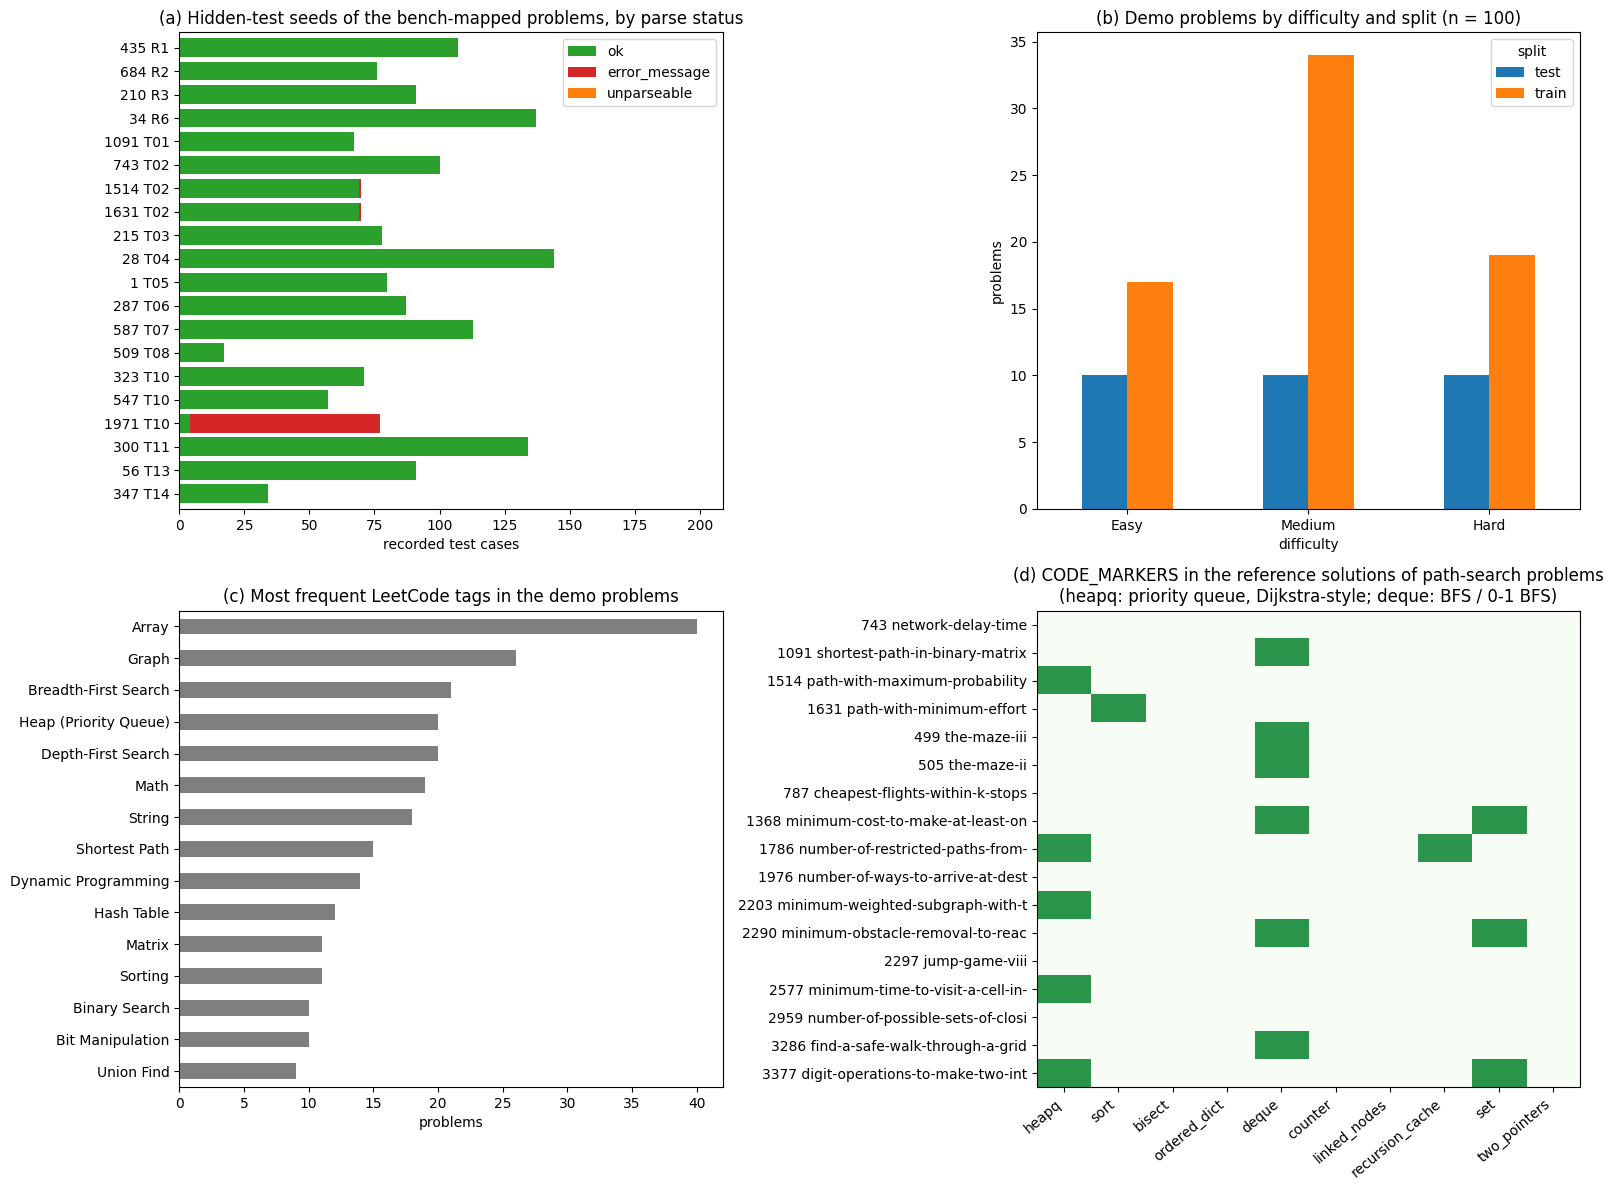


743 network-delay-time -> T02_weighted_shortest_path (primary_seed)
   answer semantics: scalar: max over nodes of the shortest distance from k, -1 if any node is unreachable; T02 recomputes a path per (start, goal)
   leetcodedataset:743:0      ok                        {'times': [[1, 2, 10], [2, 3, 10], [1, 3, 1]], 'n': 3, 'k': 1} -> 10
   leetcodedataset:743:1      ok                        {'times': [[1, 2, 1]], 'n': 2, 'k': 1} -> 1

1971 find-if-path-exists-in-graph -> T10_connected_components (alternate_seed)
   answer semantics: bool: destination reachable from source
   leetcodedataset:1971:7     ok                        {'n': 1, 'edges': [], 'source': 0, 'destination': 0} -> True
   leetcodedataset:1971:14    ok                        {'n': 100, 'edges': [], 'source': 0, 'destination': 99} -> False
   leetcodedataset:1971:0     expected_is_error_message n = 6, edges = [[0,1],[0,2],[3,5],[5,4],[4,3]], source = 0, destination = 5 -> Error: maximum recursion depth exceeded


In [22]:
# Read back what main() wrote and compare it with the published full_data_out.json (values stored in the demo data)
doc = json.loads(Path(OUT).read_text())
examples = [ex for d in doc["datasets"] if d["dataset"] == "leetcodedataset" for ex in d["examples"]]
published = {r["question_id"]: r for r in data["full_run_reference"]}


def digest(ex: dict) -> str:
    """sha1 of an example without its position fields, as make_mini_demo_data.py hashed the published one."""
    core = {k: v for k, v in ex.items() if k not in ("metadata_row_index", "metadata_duplicate_of")}
    return hashlib.sha1(json.dumps(core, ensure_ascii=False, sort_keys=True).encode()).hexdigest()


same = {ex["metadata_question_id"]: digest(ex) == published[ex["metadata_question_id"]]["example_sha1"] for ex in examples}
s = doc["metadata"]["summary"]["leetcodedataset"]
src = s["sources"]["leetcodedataset"]
print(f"{OUT}: {s['n_examples']} examples ({s['mb']} MB) from {src['repo_or_url']}@{src['revision'][:7]}, licence {s['licence']}")
print(f"identical to the published full_data_out.json example (ignoring row indices): {sum(same.values())}/{len(same)}")

# 1) The bench-mapped problems: hidden-test seeds and reference checks
COLUMNS = ["qid", "problem", "bench_task", "role", "difficulty", "cases", "ok", "error_message", "unparseable",
           "expected_null", "reference_passes", "same_as_published"]
rows = []
for ex in examples:
    if ex["metadata_bench_task"] is None:
        continue
    status = Counter(c["status"] for c in json.loads(ex["metadata_test_cases_json"]))
    rows.append([ex["metadata_question_id"], ex["metadata_task_slug"], ex["metadata_bench_task"], ex["metadata_bench_role"],
                 ex["metadata_difficulty"], ex["metadata_n_test_cases"], status["ok"], status["expected_is_error_message"],
                 status["unparseable"], ex["metadata_n_expected_null"], ex["metadata_reference_passes_check"],
                 same[ex["metadata_question_id"]]])
bench = pd.DataFrame(rows, columns=COLUMNS).sort_values(["bench_task", "qid"]).reset_index(drop=True)
display(bench)

# 2) data.py's CODE_MARKERS on the reference solutions of the path-search problems (T01/T02 seeds + 'Shortest Path')
path_like = [ex for ex in examples if ex["metadata_bench_task"] in ("T01_grid_path", "T02_weighted_shortest_path")
             or "Shortest Path" in ex["metadata_tags"]]
markers = pd.DataFrame([[int(bool(re.search(rx, ex["output"]))) for rx in CODE_MARKERS.values()] for ex in path_like],
                       index=[f"{ex['metadata_question_id']} {ex['metadata_task_slug'][:32]}" for ex in path_like],
                       columns=list(CODE_MARKERS))

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax = axes[0, 0]
if len(bench):
    t = bench.set_index(bench["qid"].astype(str) + " " + bench["bench_task"].str.split("_").str[0]).iloc[::-1]
    t[["ok", "error_message", "unparseable"]].plot.barh(stacked=True, ax=ax, width=0.8,
                                                        color=["tab:green", "tab:red", "tab:orange"])
    ax.set_xlim(0, t["cases"].max() * 1.45)  # room for the legend
    ax.legend(loc="upper right")
ax.set_xlabel("recorded test cases")
ax.set_ylabel("")
ax.set_title("(a) Hidden-test seeds of the bench-mapped problems, by parse status")

ax = axes[0, 1]
diff = pd.crosstab(pd.Series([ex["metadata_difficulty"] for ex in examples], name="difficulty"),
                   pd.Series([ex["metadata_source_split"] for ex in examples], name="split"))
diff.reindex(["Easy", "Medium", "Hard"]).fillna(0).plot.bar(ax=ax, rot=0)
ax.set_ylabel("problems")
ax.set_title(f"(b) Demo problems by difficulty and split (n = {len(examples)})")

ax = axes[1, 0]
tags = pd.Series(Counter(tag for ex in examples for tag in ex["metadata_tags"]), dtype=float).sort_values().tail(15)
if len(tags):
    tags.plot.barh(ax=ax, color="tab:gray")
ax.set_xlabel("problems")
ax.set_title("(c) Most frequent LeetCode tags in the demo problems")

ax = axes[1, 1]
if len(markers):
    ax.imshow(markers.to_numpy(), cmap="Greens", aspect="auto", vmin=0, vmax=1.4)
    ax.set_xticks(range(markers.shape[1]), markers.columns, rotation=40, ha="right")
    ax.set_yticks(range(markers.shape[0]), markers.index)
else:
    ax.text(0.5, 0.5, f"no path-search problem among the first {MAX_ROWS_PER_FILE} rows", ha="center", va="center")
    ax.set_axis_off()
ax.set_title("(d) CODE_MARKERS in the reference solutions of path-search problems\n(heapq: priority queue, Dijkstra-style; deque: BFS / 0-1 BFS)")
plt.tight_layout()
plt.show()

# 3) What parsed hidden-test seeds look like: T02 (743 network delay time) and the 1971 error-message defect
for qid in (743, 1971):
    ex = next((e for e in examples if e["metadata_question_id"] == qid), None)
    if ex is None:
        print(f"\n{qid}: not among the first MAX_ROWS_PER_FILE = {MAX_ROWS_PER_FILE} rows")
        continue
    cases = json.loads(ex["metadata_test_cases_json"])
    print(f"\n{qid} {ex['metadata_task_slug']} -> {ex['metadata_bench_task']} ({ex['metadata_bench_role']})")
    print("   answer semantics:", ex["metadata_leetcode_answer_semantics"])
    for c in [c for c in cases if c["status"] == "ok"][:2] + [c for c in cases if c["status"] != "ok"][:1]:
        shown = (c["kwargs"], c["expected"]) if c["status"] == "ok" else (c["raw_input"], c["raw_output"])
        print(f"   {c['case_id']:<26} {c['status']:<25} {str(shown[0])[:90]} -> {str(shown[1])[:60]}")

**Reading the results** (all 100 demo rows):
- **Hidden-test seeds.** Every bench-mapped problem gets parsed hidden-test seeds: 1,626 of the 1,701 recorded cases parse. The other 75 are the error-message defect: 73 of 77 for 1971, and one each for 1514 and 1631. They are flagged, not dropped, and no case is unparseable. Two-sum keeps its 8 no-solution cases (`expected = None`). Every reference solution passes its own `check()`.
- **Reproduction.** The rebuilt examples are identical to the published ones, apart from the row indices, which count positions within the subset. The demo therefore exercises exactly the code path of the full build.
- **Panel (d): why `CODE_MARKERS` are hints, not labels.** The reference solutions of the path-search problems use many algorithms:
  - a heap catches Dijkstra with a priority queue (1514, 1786, 2203, 2577, 3377);
  - a deque catches BFS and 0-1 BFS (1091, 499, 505, 1368, 2290, 3286);
  - no marker fires on an array-based O(n²) Dijkstra (the T02 seed 743 itself, and 1976), on Bellman–Ford rounds (787), or on Floyd–Warshall (2959).

  That spread of algorithms across one task family is what the bench measures in LLM-written code, and it is why labelling needs more than regexes.